In [ ]:
# Core
import os, gc
import numpy as np
import pandas as pd

# Plotting
import matplotlib.pyplot as plt
import seaborn as sns

# Modeling (used in later steps)
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.pipeline import Pipeline
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import ComplementNB, MultinomialNB
from sklearn.svm import LinearSVC

# Evaluation (used in later steps)
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, average_precision_score, confusion_matrix,
                             roc_curve, precision_recall_curve, classification_report)
from statsmodels.stats.proportion import proportion_confint   # Wilson CIs for subgroup FPRs

SEED = 42                      # use this everywhere randomness appears (splits, models)
np.random.seed(SEED)
pd.set_option("display.max_columns", 60)

In [ ]:
from google.colab import drive
drive.mount("/content/drive")

DATA_PATH = "/content/drive/MyDrive/COSC74_project/train.csv"

full = pd.read_csv(DATA_PATH)
print(f"Loaded {len(full):,} rows x {full.shape[1]} columns")
full.head()

Mounted at /content/drive
Loaded 1,804,874 rows x 45 columns


,id,target,comment_text,severe_toxicity,obscene,identity_attack,insult,threat,asian,atheist,bisexual,black,buddhist,christian,female,heterosexual,hindu,homosexual_gay_or_lesbian,intellectual_or_learning_disability,jewish,latino,male,muslim,other_disability,other_gender,other_race_or_ethnicity,other_religion,other_sexual_orientation,physical_disability,psychiatric_or_mental_illness,transgender,white,created_date,publication_id,parent_id,article_id,rating,funny,wow,sad,likes,disagree,sexual_explicit,identity_annotator_count,toxicity_annotator_count
0,59848,0.000000,"This is so cool. It's like, 'would you want yo...",0.000000,0.0,0.000000,0.00000,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2015-09-29 10:50:41.987077+00,2,NaN,2006,rejected,0,0,0,0,0,0.0,0,4
1,59849,0.000000,Thank you!! This would make my life a lot less...,0.000000,0.0,0.000000,0.00000,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2015-09-29 10:50:42.870083+00,2,NaN,2006,rejected,0,0,0,0,0,0.0,0,4
2,59852,0.000000,This is such an urgent design problem; kudos t...,0.000000,0.0,0.000000,0.00000,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2015-09-29 10:50:45.222647+00,2,NaN,2006,rejected,0,0,0,0,0,0.0,0,4
3,59855,0.000000,Is this something I'll be able to install on m...,0.000000,0.0,0.000000,0.00000,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2015-09-29 10:50:47.601894+00,2,NaN,2006,rejected,0,0,0,0,0,0.0,0,4
4,59856,0.893617,haha you guys are a bunch of losers.,0.021277,0.0,0.021277,0.87234,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.25,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,2015-09-29 10:50:48.488476+00,2,NaN,2006,rejected,0,0,0,1,0,0.0,4,47


In [ ]:
IDENTITY_CATEGORIES = {
    "gender":             ["male", "female", "transgender", "other_gender"],
    "sexual_orientation": ["heterosexual", "homosexual_gay_or_lesbian", "bisexual",
                           "other_sexual_orientation"],
    "religion":           ["christian", "jewish", "muslim", "hindu", "buddhist", "atheist",
                           "other_religion"],
    "race_ethnicity":     ["black", "white", "asian", "latino", "other_race_or_ethnicity"],
    "disability":         ["physical_disability", "intellectual_or_learning_disability",
                           "psychiatric_or_mental_illness", "other_disability"],
}
IDENTITY_COLS = [c for cols in IDENTITY_CATEGORIES.values() for c in cols]   # 24 columns
SUBTYPE_COLS = ["severe_toxicity", "obscene", "identity_attack", "insult", "threat",
                "sexual_explicit"]
NON_FEATURE_COLS = (["target"] + SUBTYPE_COLS + IDENTITY_COLS +
                    ["rating", "funny", "wow", "sad", "likes", "disagree",
                     "identity_annotator_count", "toxicity_annotator_count",
                     "created_date", "publication_id", "parent_id", "article_id"])

In [ ]:
#Keep only identity annotated columns
N_FULL = len(full)
annotated = full["identity_annotator_count"] > 0
df = full.loc[annotated].reset_index(drop=True).copy()

del full, annotated   # frees a lot of RAM; comment out if you need the full file later
gc.collect()

print(f"Working subset: {len(df):,} of {N_FULL:,} comments")

Working subset: 405,130 of 1,804,874 comments


In [ ]:
#uses a threshold of 0.5 to convert data into binary labels

TOXIC_THRESHOLD = 0.5
IDENTITY_THRESHOLD = 0.5

df["toxic"] = (df["target"] >= TOXIC_THRESHOLD).astype(int)

# One True/False column per identity, e.g. "muslim_mentioned".
# Assigning (instead of concatenating) overwrites the columns if this cell is re-run.
MENTION_COLS = [f"{c}_mentioned" for c in IDENTITY_COLS]
mentioned = df[IDENTITY_COLS].ge(IDENTITY_THRESHOLD)
mentioned.columns = MENTION_COLS
df[MENTION_COLS] = mentioned

# Category-level flags, e.g. "religion_mentioned" = mentions any religion
for cat, cols in IDENTITY_CATEGORIES.items():
    df[f"{cat}_mentioned"] = df[[f"{c}_mentioned" for c in cols]].any(axis=1)

df["n_identities_mentioned"] = mentioned.sum(axis=1)
df["any_identity"] = df["n_identities_mentioned"] > 0
df["background"] = ~df["any_identity"]

CATEGORY_COLS = [f"{cat}_mentioned" for cat in IDENTITY_CATEGORIES]
df[["id", "target", "toxic", "n_identities_mentioned", "any_identity"] + CATEGORY_COLS].head()

,id,target,toxic,n_identities_mentioned,any_identity,gender_mentioned,sexual_orientation_mentioned,religion_mentioned,race_ethnicity_mentioned,disability_mentioned
0,59856,0.893617,1,0,False,False,False,False,False,False
1,239579,0.440000,0,1,True,True,False,False,False,False
2,239592,0.500000,1,0,False,False,False,False,False,False
3,239593,0.000000,0,0,False,False,False,False,False,False
4,239607,0.912500,1,2,True,False,False,True,False,False


In [ ]:
n = len(df)
n_toxic = int(df["toxic"].sum())
print(f"Comments:  {n:,}")
print(f"Toxic:     {n_toxic:,} ({n_toxic / n:.2%})")
print(f"Non-toxic: {n - n_toxic:,} ({1 - n_toxic / n:.2%})")
print(f"Majority-class ('always non-toxic') accuracy on this subset: {1 - n_toxic / n:.2%}")

print(f"\nComments with target exactly 0.5 (toxic only because of >=): {(df['target'] == 0.5).sum():,}")
print(f"Borderline comments, target in [0.4, 0.6]: {df['target'].between(0.4, 0.6).sum():,}")
print(f"Identity values exactly 0.5 (mentioned only because of >=): "
      f"{int((df[IDENTITY_COLS] == 0.5).sum().sum()):,}")

print("\nNumber of identities mentioned per comment:")
print(df["n_identities_mentioned"].value_counts().sort_index().to_string())

Comments:  405,130
Toxic:     46,035 (11.36%)
Non-toxic: 359,095 (88.64%)
Majority-class ('always non-toxic') accuracy on this subset: 88.64%

Comments with target exactly 0.5 (toxic only because of >=): 13,436
Borderline comments, target in [0.4, 0.6]: 44,880
Identity values exactly 0.5 (mentioned only because of >=): 21,205

Number of identities mentioned per comment:
n_identities_mentioned
0     234826
1     119354
2      39037
3       9007
4       2144
5        560
6        137
7         47
8         10
9          5
10         2
13         1


In [ ]:
def group_table(flag_cols):
    rows = []
    for col in flag_cols:
        m = df[col]
        n_g = int(m.sum())
        n_tox = int(df.loc[m, "toxic"].sum())
        rows.append({"group": col.replace("_mentioned", ""), "n": n_g, "n_toxic": n_tox,
                     "n_nontoxic": n_g - n_tox,
                     "toxic_rate": n_tox / n_g if n_g else np.nan})
    return pd.DataFrame(rows).sort_values("n", ascending=False).reset_index(drop=True)

identity_table = group_table(MENTION_COLS + ["background"])
category_table = group_table(CATEGORY_COLS + ["any_identity", "background"])
display(identity_table)
display(category_table)

# With a 10% test split, a group needs ~1,000 non-toxic comments overall to have ~100 in test
thin = identity_table.loc[(identity_table["n_nontoxic"] < 1000) &
                          (identity_table["group"] != "background"), "group"].tolist()
print("Groups likely too small to analyze individually (pool into categories):", thin)

,group,n,n_toxic,n_nontoxic,toxic_rate
0,background,234826,18072,216754,0.076959
1,female,53429,7311,46118,0.136836
2,male,44484,6685,37799,0.150279
3,christian,40423,3673,36750,0.090864
4,white,25082,7038,18044,0.280600
5,muslim,21006,4781,16225,0.227602
6,black,14901,4678,10223,0.313939
7,homosexual_gay_or_lesbian,10997,3121,7876,0.283805
8,jewish,7651,1240,6411,0.162070
9,psychiatric_or_mental_illness,4889,1030,3859,0.210677


,group,n,n_toxic,n_nontoxic,toxic_rate
0,background,234826,18072,216754,0.076959
1,any_identity,170304,27963,142341,0.164195
2,gender,80800,11931,68869,0.147661
3,religion,63517,8557,54960,0.134720
4,race_ethnicity,39021,10312,28709,0.264268
5,sexual_orientation,11581,3219,8362,0.277955
6,disability,5024,1041,3983,0.207205


Groups likely too small to analyze individually (pool into categories): ['heterosexual', 'buddhist', 'hindu', 'other_race_or_ethnicity', 'other_religion', 'bisexual', 'intellectual_or_learning_disability', 'physical_disability', 'other_gender', 'other_sexual_orientation', 'other_disability']


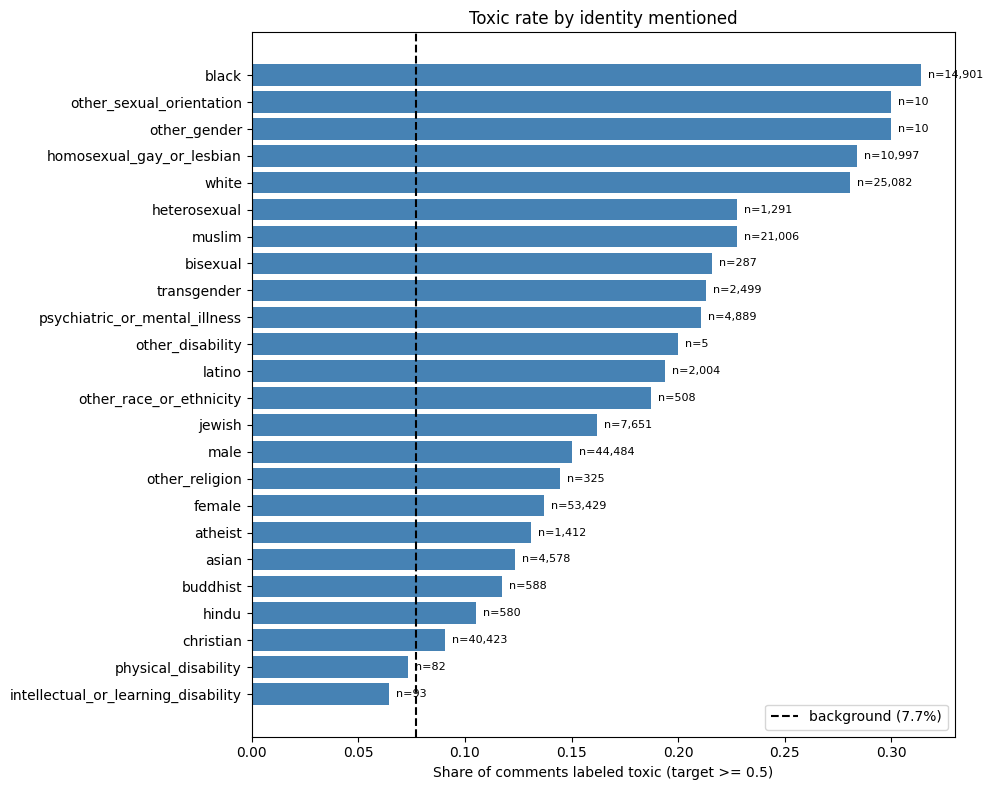

In [ ]:
plot_df = identity_table[identity_table["group"] != "background"].sort_values("toxic_rate")
bg_rate = identity_table.loc[identity_table["group"] == "background", "toxic_rate"].iloc[0]

fig, ax = plt.subplots(figsize=(10, 8))
ax.barh(plot_df["group"], plot_df["toxic_rate"], color="steelblue")
ax.axvline(bg_rate, color="black", linestyle="--", label=f"background ({bg_rate:.1%})")
for i, (rate, n_g) in enumerate(zip(plot_df["toxic_rate"], plot_df["n"])):
    ax.text(rate, i, f"  n={n_g:,}", va="center", fontsize=8)
ax.set_xlabel("Share of comments labeled toxic (target >= 0.5)")
ax.set_title("Toxic rate by identity mentioned")
ax.legend(loc="lower right")
plt.tight_layout()
plt.show()

In [ ]:
from google.colab import files

SAVE_PATH = "/content/identity_subset.parquet"   # temporary copy inside the Colab session
df.to_parquet(SAVE_PATH, index=False)
files.download(SAVE_PATH)                         # sends it to your browser's download folder

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
import os
print(f"File size: {os.path.getsize(DATA_PATH) / 1e6:,.0f} MB")

check = pd.read_csv(DATA_PATH, usecols=["id", "target", "toxicity_annotator_count"])
print(f"Rows: {len(check):,}")
print(check.tail())

File size: 816 MB
Rows: 1,804,874
              id    target  toxicity_annotator_count
1804869  6333967  0.000000                         4
1804870  6333969  0.000000                         4
1804871  6333982  0.000000                         4
1804872  6334009  0.621212                        66
1804873  6334010  0.000000                         4
